In [ ]:
import pandas as pd
from pathlib import Path


PROJECT_DIR = Path(r"D:\Engineering\Junior\SIC-AI\GraduationProject\NIH_ChestXray14_Project")

CSV_PATH = (
    PROJECT_DIR
    / "data"
    / "metadata"
    / "train.csv"
)

print("Project folder exists:", PROJECT_DIR.exists())
print("CSV file exists:", CSV_PATH.exists())
print("CSV path:", CSV_PATH)

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)

    print("\nNumber of records:", len(df))
    print("Number of unique patients:", df["Patient ID"].nunique())
    df.drop("Unnamed: 11", axis=1, inplace=True)
    display(df.head())

Project folder exists: True
CSV file exists: True
CSV path: D:\Engineering\Junior\SIC-AI\GraduationProject\NIH_ChestXray14_Project\data\metadata\train.csv

Number of records: 14950
Number of unique patients: 4529


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000003_003.png,Infiltration,3,3,76,F,PA,2698,2991,0.143,0.143
1,00000005_006.png,Infiltration,6,5,70,F,PA,2992,2991,0.143,0.143
2,00000005_007.png,Effusion|Infiltration,7,5,70,F,PA,2566,2681,0.143,0.143
3,00000008_000.png,Cardiomegaly,0,8,69,F,PA,2048,2500,0.171,0.171
4,00000008_002.png,Nodule,2,8,73,F,PA,2048,2500,0.168,0.168


Part 1 — Dataset overview

In [3]:
# 1. Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. First five records
display(df.head())

# 4. Data types and non-null counts
print("\nDataset information:")
df.info()

Number of rows: 14950
Number of columns: 11

Column names:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000003_003.png,Infiltration,3,3,76,F,PA,2698,2991,0.143,0.143
1,00000005_006.png,Infiltration,6,5,70,F,PA,2992,2991,0.143,0.143
2,00000005_007.png,Effusion|Infiltration,7,5,70,F,PA,2566,2681,0.143,0.143
3,00000008_000.png,Cardiomegaly,0,8,69,F,PA,2048,2500,0.171,0.171
4,00000008_002.png,Nodule,2,8,73,F,PA,2048,2500,0.168,0.168



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14950 entries, 0 to 14949
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Image Index                  14950 non-null  object 
 1   Finding Labels               14950 non-null  object 
 2   Follow-up #                  14950 non-null  int64  
 3   Patient ID                   14950 non-null  int64  
 4   Patient Age                  14950 non-null  int64  
 5   Patient Gender               14950 non-null  object 
 6   View Position                14950 non-null  object 
 7   OriginalImage[Width          14950 non-null  int64  
 8   Height]                      14950 non-null  int64  
 9   OriginalImagePixelSpacing[x  14950 non-null  float64
 10  y]                           14950 non-null  float64
dtypes: float64(2), int64(5), object(4)
memory usage: 1.3+ MB


Check missing values and duplicates

In [4]:
# Missing values in each column
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

display(missing_summary)

# Duplicate rows
print("Completely duplicated rows:", df.duplicated().sum())

# Duplicate image filenames
print("Duplicate image filenames:",
      df["Image Index"].duplicated().sum())

# Duplicate patient IDs are expected!
print("Unique patients:", df["Patient ID"].nunique())

,Missing_Count,Missing_Percentage
Image Index,0,0.0
Finding Labels,0,0.0
Follow-up #,0,0.0
Patient ID,0,0.0
Patient Age,0,0.0
Patient Gender,0,0.0
View Position,0,0.0
OriginalImage[Width,0,0.0
Height],0,0.0
OriginalImagePixelSpacing[x,0,0.0


Completely duplicated rows: 0
Duplicate image filenames: 0
Unique patients: 4529


Part 2 — Patient-level analysis

How many images does each patient have?

In [5]:
images_per_patient = df.groupby("Patient ID").size()

print("Total unique patients:", len(images_per_patient))
print("\nImages per patient:")
display(images_per_patient.describe())

print("\nPatients with the most images:")
display(
    images_per_patient
    .sort_values(ascending=False)
    .head(10)
    .rename("Number_of_Images")
    .to_frame()
)

Total unique patients: 4529

Images per patient:


count    4529.000000
mean        3.300949
std         5.375987
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        73.000000
dtype: float64


Patients with the most images:


,Number_of_Images
Patient ID,
6271,73
4858,65
4808,59
4893,59
3393,58
3528,58
8468,57
583,54
4344,51


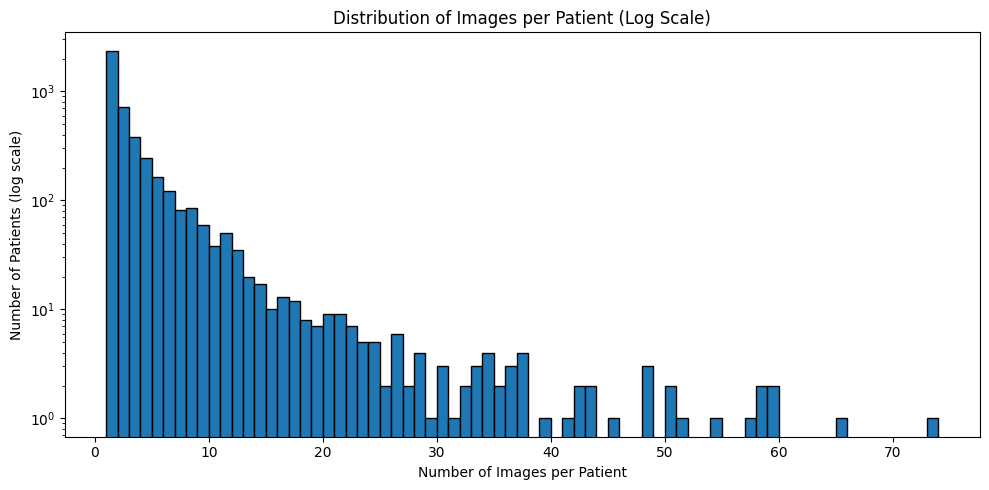

In [6]:
import matplotlib.pyplot as plt

images_per_patient = df.groupby("Patient ID").size()

plt.figure(figsize=(10, 5))

plt.hist(
    images_per_patient,
    bins=range(1, images_per_patient.max() + 2),
    log=True,
    edgecolor="black"
)

plt.title("Distribution of Images per Patient (Log Scale)")
plt.xlabel("Number of Images per Patient")
plt.ylabel("Number of Patients (log scale)")
plt.tight_layout()
plt.show()

In [7]:
print("Number of patients:", images_per_patient.size)
print("Mean images per patient:", round(images_per_patient.mean(), 2))
print("Median images per patient:", images_per_patient.median())
print("Minimum:", images_per_patient.min())
print("Maximum:", images_per_patient.max())

print(
    "Patients with one image:",
    (images_per_patient == 1).sum()
)

print(
    "Patients with multiple images:",
    (images_per_patient > 1).sum()
)

Number of patients: 4529
Mean images per patient: 3.3
Median images per patient: 1.0
Minimum: 1
Maximum: 73
Patients with one image: 2360
Patients with multiple images: 2169


Part 3 — Disease label analysis

In [10]:

# Part 3.1 — Detect available disease classes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from itertools import combinations
from IPython.display import display

# Verify the required column exists
assert "Finding Labels" in df.columns, (
    "The dataframe does not contain a 'Finding Labels' column."
)

# Extract all individual labels from the actual dataset
label_lists = (
    df["Finding Labels"]
    .dropna()
    .astype(str)
    .apply(lambda x: [
        label.strip()
        for label in x.split("|")
        if label.strip()
    ])
)

available_classes = sorted({
    label
    for labels in label_lists
    for label in labels
})

# Separate disease labels from the special No Finding label
disease_classes = [
    label for label in available_classes
    if label != "No Finding"
]

print("Dataset shape:", df.shape)
print("Unique image filenames:", df["Image Index"].nunique())
print("Number of observed label classes:", len(available_classes))
print("Number of observed disease classes:", len(disease_classes))

print("\nAll classes actually present in the new dataset:")
for i, label in enumerate(available_classes, start=1):
    print(f"{i}. {label}")

print("\nDisease classes used in the analysis:")
print(disease_classes)

print("\nNo Finding is present:", "No Finding" in available_classes)


Dataset shape: (14950, 11)
Unique image filenames: 14950
Number of observed label classes: 14
Number of observed disease classes: 13

All classes actually present in the new dataset:
1. Atelectasis
2. Cardiomegaly
3. Consolidation
4. Edema
5. Effusion
6. Emphysema
7. Fibrosis
8. Infiltration
9. Mass
10. No Finding
11. Nodule
12. Pleural_Thickening
13. Pneumonia
14. Pneumothorax

Disease classes used in the analysis:
['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']

No Finding is present: True


Create multi-label indicator columns

In [12]:

label_df = pd.DataFrame(index=df.index)

for label in available_classes:
    label_df[label] = label_lists.reindex(df.index).apply(
        lambda labels: int(label in labels)
        if isinstance(labels, list) else 0
    )

print("Label indicator dataframe shape:", label_df.shape)
display(label_df.head())


Label indicator dataframe shape: (14950, 14)


,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Infiltration,Mass,No Finding,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,1,0,0,1,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,1,0,0,0


Count each disease

In [ ]:

class_counts = (
    label_df[disease_classes]
    .sum()
    .sort_values(ascending=False)
)

class_distribution = pd.DataFrame({
    "Disease": class_counts.index,
    "Image Count": class_counts.values,
    "Percentage": class_counts.values / len(df) * 100
})

display(
    class_distribution.style.format({
        "Image Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    })
)

print("Total images:", f"{len(df):,}")
print("Observed disease classes:", len(disease_classes))


,Disease,Image Count,Percentage
0,Infiltration,"3,431",22.95%
1,Atelectasis,"2,308",15.44%
2,Effusion,"2,267",15.16%
3,Nodule,"1,249",8.35%
4,Mass,916,6.13%
5,Pneumothorax,885,5.92%
6,Consolidation,854,5.71%
7,Pleural_Thickening,680,4.55%
8,Cardiomegaly,623,4.17%
9,Emphysema,500,3.34%


Total images: 14,950
Observed disease classes: 13


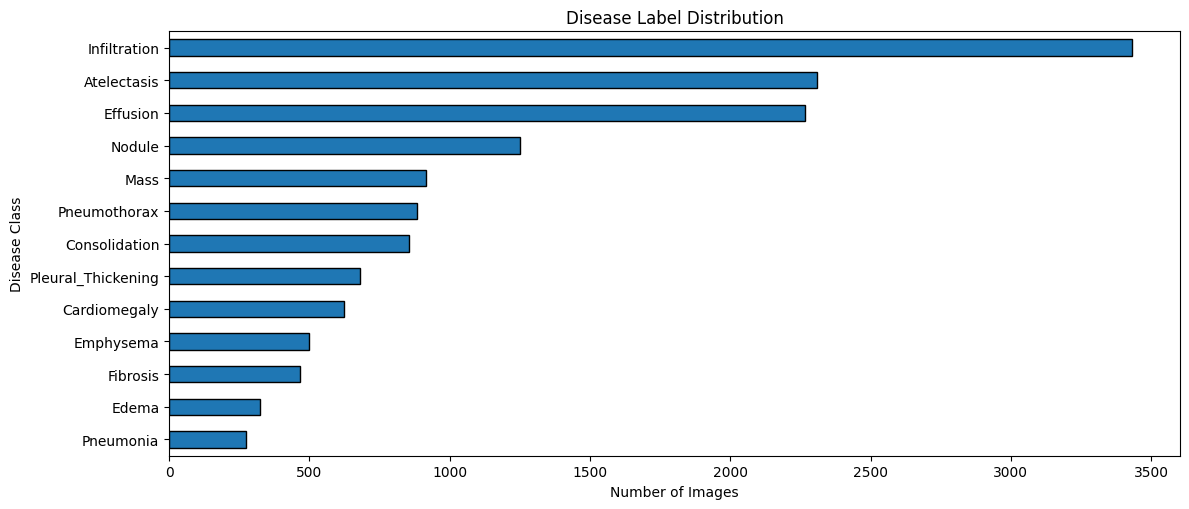

In [14]:


plt.figure(figsize=(12, max(5, len(disease_classes) * 0.4)))

class_counts.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Disease Label Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Disease Class")
plt.tight_layout()
plt.show()


Examine No Finding

In [15]:



if "No Finding" in label_df.columns:
    no_finding_count = int(label_df["No Finding"].sum())
else:
    no_finding_count = 0

no_finding_percentage = no_finding_count / len(df) * 100

# Images with one or more disease labels
if disease_classes:
    has_disease = label_df[disease_classes].sum(axis=1) > 0
    disease_image_count = int(has_disease.sum())
else:
    has_disease = pd.Series(False, index=df.index)
    disease_image_count = 0

print(f"Total images: {len(df):,}")
print(
    f"No Finding images: {no_finding_count:,} "
    f"({no_finding_percentage:.2f}%)"
)
print(
    f"Images with at least one disease label: "
    f"{disease_image_count:,} ({disease_image_count / len(df) * 100:.2f}%)"
)

# Check for rows that have No Finding and a disease label together
if "No Finding" in label_df.columns:
    inconsistent = (label_df["No Finding"] == 1) & has_disease

    print(
        "Images labeled both No Finding and a disease:",
        int(inconsistent.sum())
    )

    if inconsistent.any():
        display(
            df.loc[
                inconsistent,
                ["Image Index", "Finding Labels"]
            ].head(20)
        )


Total images: 14,950
No Finding images: 5,000 (33.44%)
Images with at least one disease label: 9,950 (66.56%)
Images labeled both No Finding and a disease: 0


Part 4 — Label combinations

Analyze disease co-occurrence

,Disease Pair,Image Count
0,Effusion + Infiltration,611
1,Atelectasis + Infiltration,571
2,Atelectasis + Effusion,553
3,Infiltration + Nodule,294
4,Consolidation + Infiltration,214
5,Atelectasis + Consolidation,196
6,Consolidation + Effusion,182
7,Infiltration + Mass,179
8,Effusion + Mass,163
9,Effusion + Pleural_Thickening,152


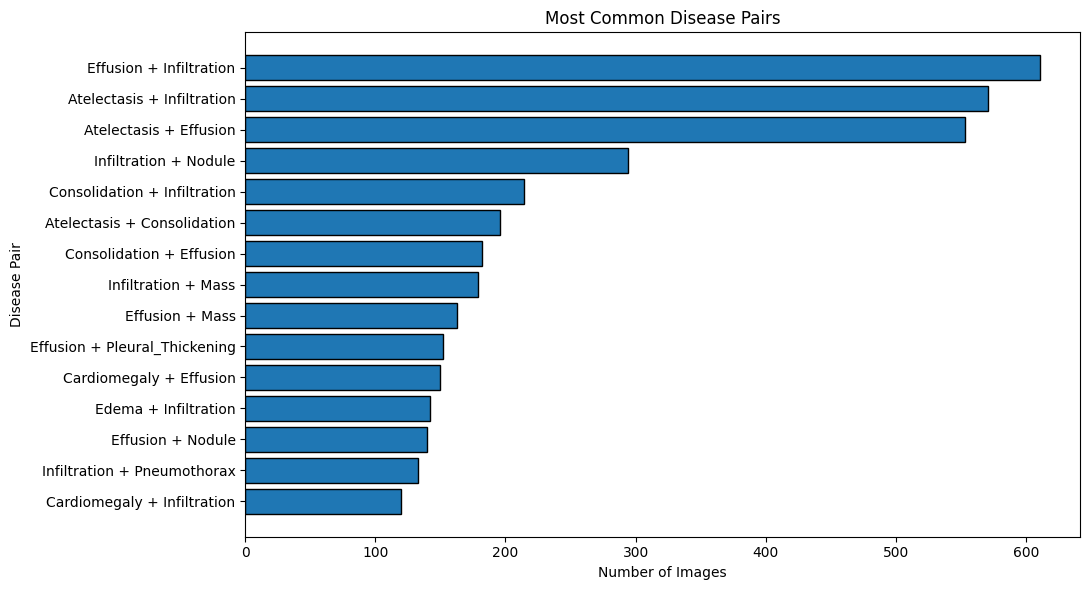

In [16]:



pair_counts = Counter()

for labels in label_lists:
    # Exclude No Finding from disease-pair analysis
    current_diseases = sorted({
        label for label in labels
        if label in disease_classes
    })

    for pair in combinations(current_diseases, 2):
        pair_counts[pair] += 1

top_pairs = pair_counts.most_common(15)

pair_df = pd.DataFrame(
    [
        {
            "Disease Pair": f"{pair[0]} + {pair[1]}",
            "Image Count": count
        }
        for pair, count in top_pairs
    ],
    columns=["Disease Pair", "Image Count"]
)

display(pair_df)

if not pair_df.empty:
    plot_pairs = pair_df.sort_values("Image Count")

    plt.figure(figsize=(11, 6))
    plt.barh(
        plot_pairs["Disease Pair"],
        plot_pairs["Image Count"],
        edgecolor="black"
    )

    plt.title("Most Common Disease Pairs")
    plt.xlabel("Number of Images")
    plt.ylabel("Disease Pair")
    plt.tight_layout()
    plt.show()
else:
    print("No co-occurring disease pairs were found.")


Part 5 — Patient demographics and view position

count    14950.000000
mean        48.474582
std         16.612676
min          1.000000
25%         38.000000
50%         50.000000
75%         60.000000
max        412.000000
Name: Patient Age, dtype: float64


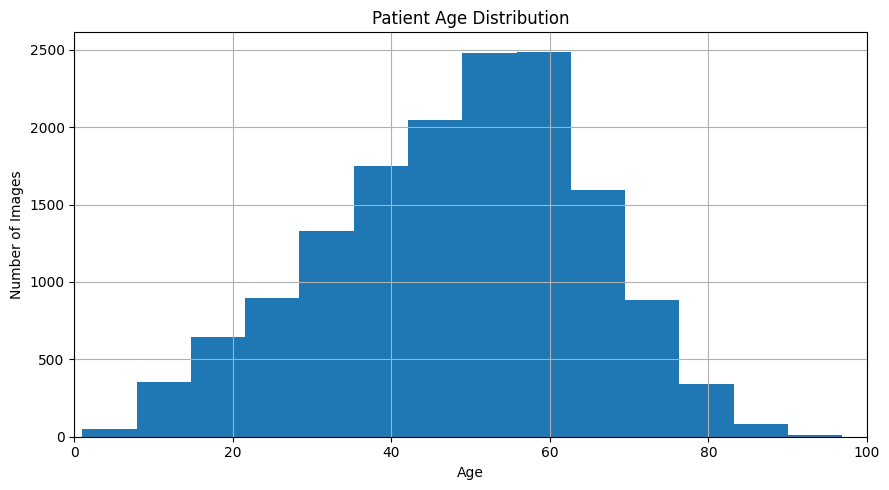

In [26]:
df["Patient Age"] = pd.to_numeric(
    df["Patient Age"], errors="coerce"
)

print(df["Patient Age"].describe())

plt.figure(figsize=(9, 5))

df["Patient Age"].dropna().hist(bins=60)

plt.xlim(0, 100)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

Patient Gender
M    8208
F    6742
Name: count, dtype: int64


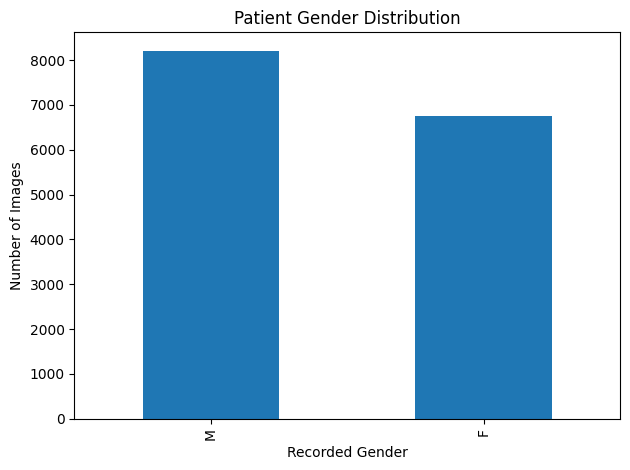

In [27]:
print(df["Patient Gender"].value_counts(dropna=False))

df["Patient Gender"].value_counts().plot(kind="bar")

plt.title("Patient Gender Distribution")
plt.xlabel("Recorded Gender")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

Disease labels by gender

,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
Gender,,,,,,,,,,,,,
F,944,394,367,146,1116,231,234,1500,352,551,316,106,426
M,1364,229,487,177,1151,269,234,1931,564,698,364,169,459


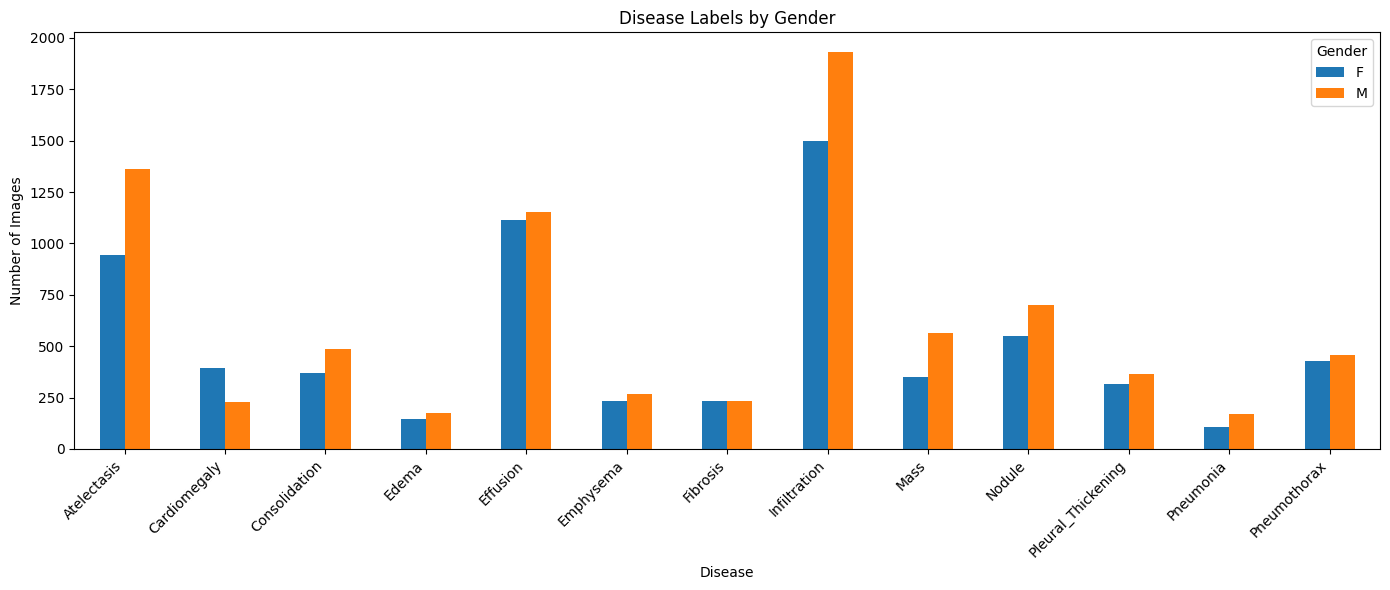

In [29]:

if "Patient Gender" in df.columns and disease_classes:
    gender_disease = label_df[disease_classes].copy()
    gender_disease["Gender"] = df["Patient Gender"].fillna("Missing")

    gender_disease_counts = gender_disease.groupby("Gender")[disease_classes].sum()

    display(gender_disease_counts)

    gender_disease_counts.T.plot(kind="bar", figsize=(14, 6))

    plt.title("Disease Labels by Gender")
    plt.xlabel("Disease")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


View Position
PA    8771
AP    6179
Name: count, dtype: int64


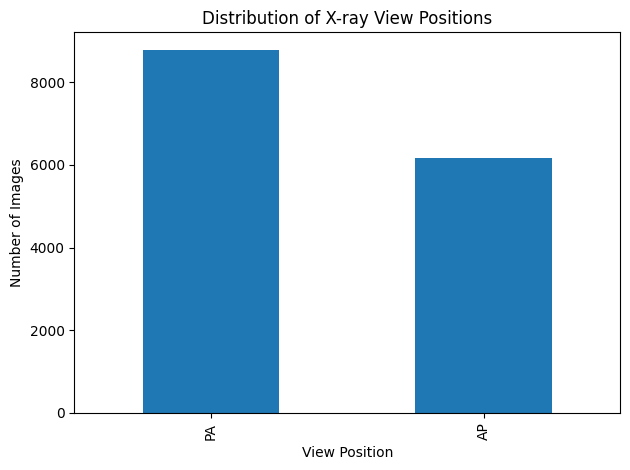

In [28]:
print(df["View Position"].value_counts(dropna=False))

df["View Position"].value_counts().plot(kind="bar")

plt.title("Distribution of X-ray View Positions")
plt.xlabel("View Position")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

Compare findings across view positions

In [ ]:


view_label_rates = (
    df.assign(**label_df[disease_classes])
      .groupby("View Position")[disease_classes]
      .mean() * 100
)

display(view_label_rates.round(2))

,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
View Position,,,,,,,,,,,,,
AP,18.95,3.67,9.14,4.48,17.62,3.64,1.00,30.54,5.81,7.23,2.27,2.09,5.29
PA,12.96,4.51,3.29,0.52,13.43,3.14,4.63,17.60,6.35,9.14,6.16,1.66,6.36


<Figure size 1400x500 with 0 Axes>

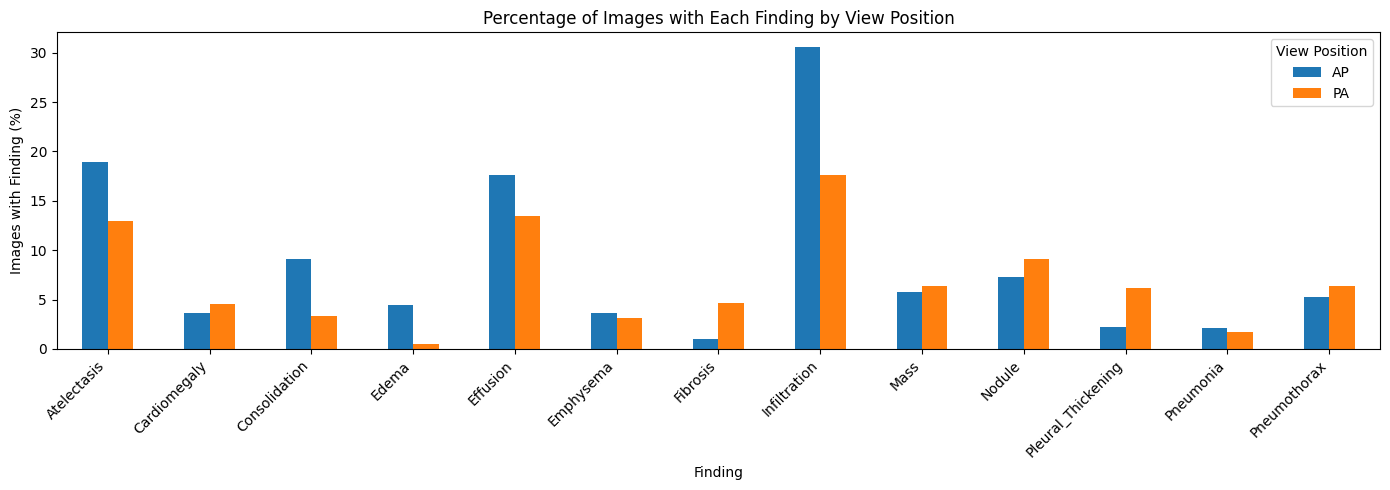

In [36]:
plt.figure(figsize=(14, 5))

view_label_rates.T.plot(kind="bar", figsize=(14, 5))

plt.title("Percentage of Images with Each Finding by View Position")
plt.xlabel("Finding")
plt.ylabel("Images with Finding (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Differences here do not automatically mean the view causes disease or changes the label. Patient populations, examination settings, and label prevalence can differ across views.

After Augmentation

In [1]:
import pandas as pd
from pathlib import Path


PROJECT_DIR = Path(r"D:\Engineering\Junior\SIC-AI\GraduationProject\NIH_ChestXray14_Project")

CSV_PATH = (
    PROJECT_DIR
    / "data"
    / "metadata"
    / "combined.csv"
)

print("Project folder exists:", PROJECT_DIR.exists())
print("CSV file exists:", CSV_PATH.exists())
print("CSV path:", CSV_PATH)

if CSV_PATH.exists():
    augmented_df = pd.read_csv(CSV_PATH)

    print("\nNumber of records:", len(augmented_df))
    print("Number of unique patients:", augmented_df["Patient ID"].nunique())
    augmented_df.drop("Unnamed: 11", axis=1, inplace=True)
    display(augmented_df.head())

Project folder exists: True
CSV file exists: True
CSV path: D:\Engineering\Junior\SIC-AI\GraduationProject\NIH_ChestXray14_Project\data\metadata\combined.csv

Number of records: 26530
Number of unique patients: 6473


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000003_003.png,Infiltration,3.0,3.0,76.0,F,PA,2698.0,2991.0,0.143,0.143
1,00000005_006.png,Infiltration,6.0,5.0,70.0,F,PA,2992.0,2991.0,0.143,0.143
2,00000005_007.png,Effusion|Infiltration,7.0,5.0,70.0,F,PA,2566.0,2681.0,0.143,0.143
3,00000008_000.png,Cardiomegaly,0.0,8.0,69.0,F,PA,2048.0,2500.0,0.171,0.171
4,00000008_002.png,Nodule,2.0,8.0,73.0,F,PA,2048.0,2500.0,0.168,0.168


In [3]:
# Remove all records containing the Hernia label

before_count = len(augmented_df)

augmented_df = augmented_df[
    ~augmented_df["Finding Labels"]
    .fillna("")
    .apply(lambda labels: "Hernia" in [label.strip() for label in labels.split("|")])
].copy()

after_count = len(augmented_df)

print("Records before removing Hernia:", before_count)
print("Records removed:", before_count - after_count)
print("Records remaining:", after_count)
print("Unique patients remaining:", augmented_df["Patient ID"].nunique())

# Verify that no Hernia labels remain
print(
    "Remaining Hernia labels:",
    augmented_df["Finding Labels"]
    .fillna("")
    .apply(lambda labels: "Hernia" in [label.strip() for label in labels.split("|")])
    .sum()
)

display(augmented_df.head())

Records before removing Hernia: 26530
Records removed: 30
Records remaining: 26500
Unique patients remaining: 6467
Remaining Hernia labels: 0


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000003_003.png,Infiltration,3.0,3.0,76.0,F,PA,2698.0,2991.0,0.143,0.143
1,00000005_006.png,Infiltration,6.0,5.0,70.0,F,PA,2992.0,2991.0,0.143,0.143
2,00000005_007.png,Effusion|Infiltration,7.0,5.0,70.0,F,PA,2566.0,2681.0,0.143,0.143
3,00000008_000.png,Cardiomegaly,0.0,8.0,69.0,F,PA,2048.0,2500.0,0.171,0.171
4,00000008_002.png,Nodule,2.0,8.0,73.0,F,PA,2048.0,2500.0,0.168,0.168


Class Counts After Augmentation

In [4]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Split the findings for each image
label_lists = (
    augmented_df["Finding Labels"]
    .fillna("")
    .apply(lambda x: [label.strip() for label in x.split("|") if label.strip()])
)

# Count each individual label
class_counts = Counter(
    label
    for labels in label_lists
    for label in labels
)

# Convert to a DataFrame
class_counts_df = (
    pd.DataFrame(class_counts.items(), columns=["Class", "Image Count"])
    .sort_values("Image Count", ascending=False)
    .reset_index(drop=True)
)

display(class_counts_df)

,Class,Image Count
0,Infiltration,7824
1,No Finding,5000
2,Atelectasis,4931
3,Effusion,4497
4,Mass,2760
5,Nodule,2529
6,Consolidation,2526
7,Pneumothorax,1983
8,Pleural_Thickening,1906
9,Cardiomegaly,1384


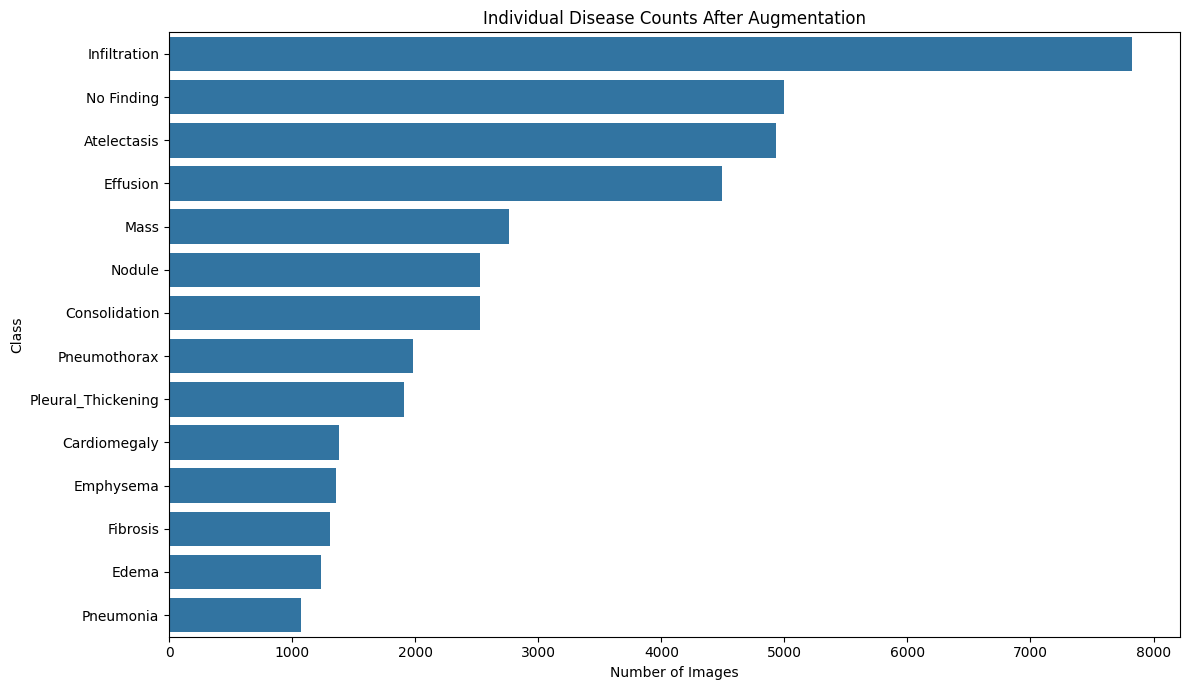

In [5]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=class_counts_df,
    x="Image Count",
    y="Class"
)

plt.title("Individual Disease Counts After Augmentation")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

Compare before and after augmentation

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

# ==================================================
# 1. PATHS
# ==================================================

PROJECT_DIR = Path(
    r"D:\Engineering\Junior\SIC-AI\GraduationProject\NIH_ChestXray14_Project"
)

BEFORE_PATH = (
    PROJECT_DIR
    / "data"
    / "metadata"
    / "train.csv"
)

AFTER_PATH = (
    PROJECT_DIR
    / "data"
    / "metadata"
    / "after_augmentation_train.csv"
)

LABEL_COLUMN = "Finding Labels"

# ==================================================
# 2. CHECK PATHS
# ==================================================

print("Project folder exists:", PROJECT_DIR.exists())
print("Original CSV exists:", BEFORE_PATH.exists())
print("Augmented CSV exists:", AFTER_PATH.exists())

if not BEFORE_PATH.exists():
    raise FileNotFoundError(f"Original CSV not found: {BEFORE_PATH}")

if not AFTER_PATH.exists():
    raise FileNotFoundError(f"Augmented CSV not found: {AFTER_PATH}")

# ==================================================
# 3. LOAD DATASETS
# ==================================================

df = pd.read_csv(BEFORE_PATH)
augmented_df = pd.read_csv(AFTER_PATH)

# Remove unwanted columns if present
df.drop(columns=["Unnamed: 11"], errors="ignore", inplace=True)
augmented_df.drop(columns=["Unnamed: 11"], errors="ignore", inplace=True)

# Check label columns
if LABEL_COLUMN not in df.columns:
    raise ValueError(f"'{LABEL_COLUMN}' not found in train.csv")

if LABEL_COLUMN not in augmented_df.columns:
    raise ValueError(
        f"'{LABEL_COLUMN}' not found in after_augmentation_train.csv. "
        f"Available columns: {augmented_df.columns.tolist()}"
    )

# ==================================================
# 4. DATASET OVERVIEW
# ==================================================

print("\n" + "=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

print(f"Records before augmentation: {len(df):,}")
print(f"Records after augmentation:  {len(augmented_df):,}")
print(f"Additional records:          {len(augmented_df) - len(df):,}")

print(
    f"Percentage increase in rows: "
    f"{(len(augmented_df) - len(df)) / len(df) * 100:.2f}%"
    if len(df) > 0 else "Percentage increase: undefined"
)

if "Patient ID" in df.columns:
    print(
        "Unique patients before augmentation:",
        df["Patient ID"].nunique()
    )

if "Patient ID" in augmented_df.columns:
    print(
        "Unique patients after augmentation:",
        augmented_df["Patient ID"].nunique()
    )

print("\nOriginal columns:", df.columns.tolist())
print("Augmented columns:", augmented_df.columns.tolist())

Project folder exists: True
Original CSV exists: True
Augmented CSV exists: True

DATASET OVERVIEW
Records before augmentation: 14,950
Records after augmentation:  19,326
Additional records:          4,376
Percentage increase in rows: 29.27%
Unique patients before augmentation: 4529
Unique patients after augmentation: 4529

Original columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']
Augmented columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']


Calculate individual disease counts

In [7]:
def calculate_class_counts(dataframe, label_column):
    label_lists = (
        dataframe[label_column]
        .fillna("")
        .astype(str)
        .apply(
            lambda value: [
                label.strip()
                for label in value.split("|")
                if label.strip()
            ]
        )
    )

    class_counts = Counter(
        label
        for labels in label_lists
        for label in labels
    )

    result = pd.DataFrame(
        class_counts.items(),
        columns=["Class", "Count"]
    )

    return result.sort_values(
        "Count", ascending=False
    ).reset_index(drop=True)


# Calculate counts for both datasets
counts_before = calculate_class_counts(
    df, LABEL_COLUMN
).rename(columns={"Count": "Count Before"})

counts_after = calculate_class_counts(
    augmented_df, LABEL_COLUMN
).rename(columns={"Count": "Count After"})

print("CLASS COUNTS BEFORE AUGMENTATION")
display(counts_before)

print("CLASS COUNTS AFTER AUGMENTATION")
display(counts_after)

CLASS COUNTS BEFORE AUGMENTATION


,Class,Count Before
0,No Finding,5000
1,Infiltration,3431
2,Atelectasis,2308
3,Effusion,2267
4,Nodule,1249
5,Mass,916
6,Pneumothorax,885
7,Consolidation,854
8,Pleural_Thickening,680
9,Cardiomegaly,623


CLASS COUNTS AFTER AUGMENTATION


,Class,Count After
0,No Finding,5000
1,Infiltration,4430
2,Effusion,3016
3,Atelectasis,2916
4,Mass,1670
5,Pneumothorax,1615
6,Nodule,1555
7,Consolidation,1502
8,Pleural_Thickening,1360
9,Cardiomegaly,1197


In [8]:
comparison_df = pd.merge(
    counts_before,
    counts_after,
    on="Class",
    how="outer"
).fillna(0)

comparison_df[["Count Before", "Count After"]] = (
    comparison_df[["Count Before", "Count After"]]
    .astype(int)
)

comparison_df["Labels Added"] = (
    comparison_df["Count After"]
    - comparison_df["Count Before"]
)

comparison_df["Growth (%)"] = np.where(
    comparison_df["Count Before"] > 0,
    comparison_df["Labels Added"]
    / comparison_df["Count Before"] * 100,
    np.nan
)

comparison_df = comparison_df.sort_values(
    "Count Before", ascending=False
).reset_index(drop=True)

print("CLASS COUNT COMPARISON")
display(
    comparison_df.style.format({
        "Count Before": "{:,.0f}",
        "Count After": "{:,.0f}",
        "Labels Added": "{:+,.0f}",
        "Growth (%)": "{:+.2f}%"
    })
)

CLASS COUNT COMPARISON


,Class,Count Before,Count After,Labels Added,Growth (%)
0,No Finding,"5,000","5,000",+0,+0.00%
1,Infiltration,"3,431","4,430",+999,+29.12%
2,Atelectasis,"2,308","2,916",+608,+26.34%
3,Effusion,"2,267","3,016",+749,+33.04%
4,Nodule,"1,249","1,555",+306,+24.50%
5,Mass,916,"1,670",+754,+82.31%
6,Pneumothorax,885,"1,615",+730,+82.49%
7,Consolidation,854,"1,502",+648,+75.88%
8,Pleural_Thickening,680,"1,360",+680,+100.00%
9,Cardiomegaly,623,"1,197",+574,+92.13%


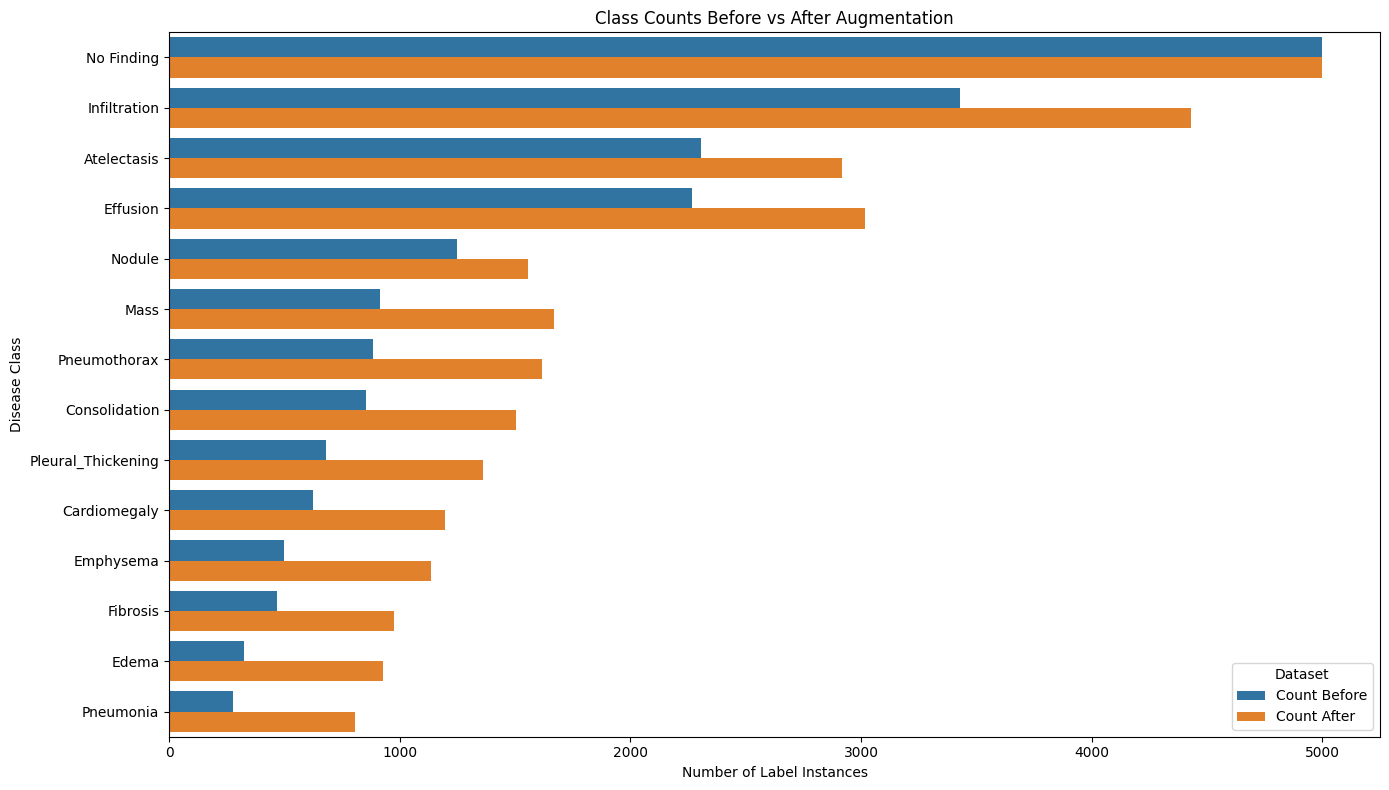

In [9]:
plot_df = comparison_df.melt(
    id_vars="Class",
    value_vars=["Count Before", "Count After"],
    var_name="Dataset",
    value_name="Label Count"
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=plot_df,
    x="Label Count",
    y="Class",
    hue="Dataset"
)

plt.title("Class Counts Before vs After Augmentation")
plt.xlabel("Number of Label Instances")
plt.ylabel("Disease Class")
plt.tight_layout()
plt.show()

CLASS PROPORTIONS


,Class,Share Before (%),Share After (%),Share Change (pp)
0,No Finding,25.279,17.790,-7.490
1,Infiltration,17.347,15.762,-1.585
2,Atelectasis,11.669,10.375,-1.294
3,Effusion,11.462,10.731,-0.731
4,Nodule,6.315,5.533,-0.782
5,Mass,4.631,5.942,1.311
6,Pneumothorax,4.474,5.746,1.272
7,Consolidation,4.318,5.344,1.026
8,Pleural_Thickening,3.438,4.839,1.401
9,Cardiomegaly,3.150,4.259,1.109


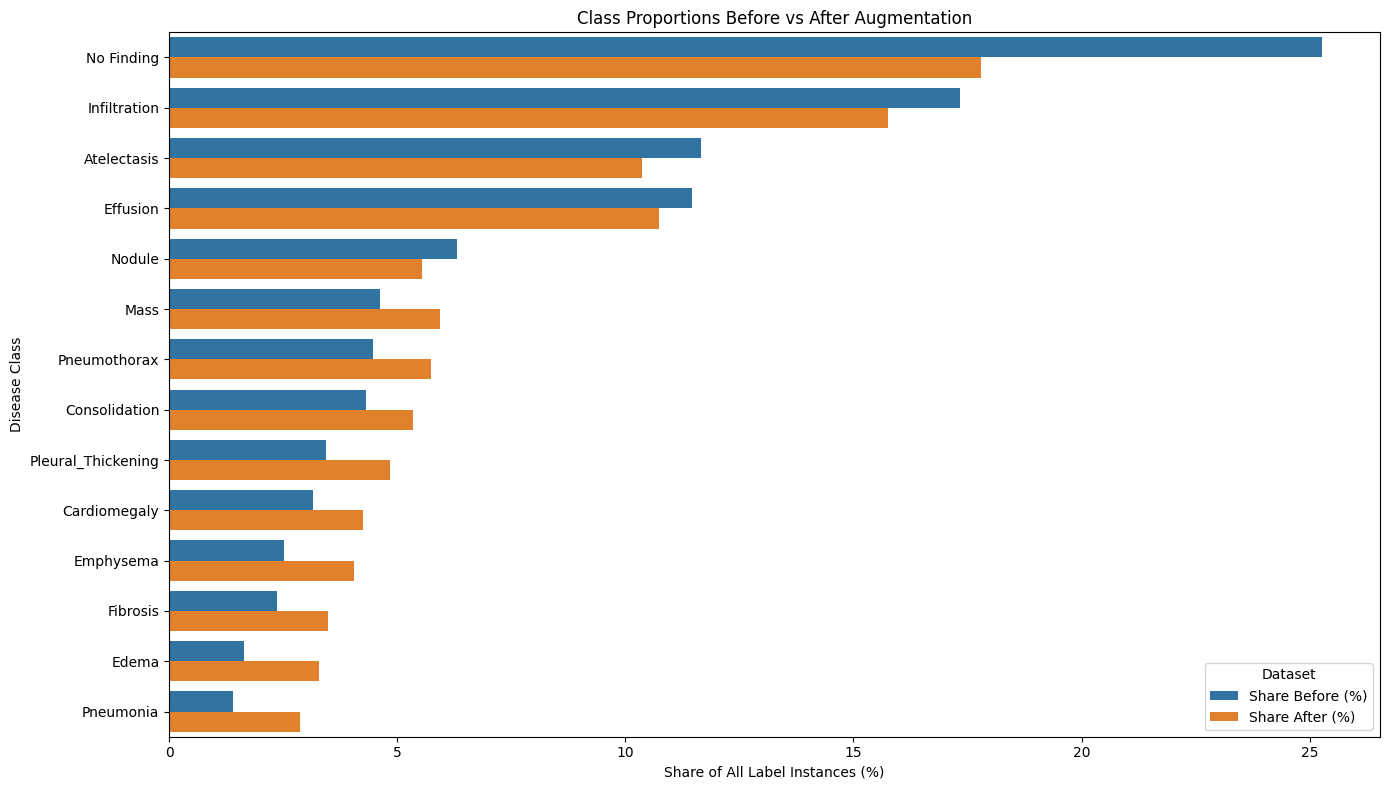

In [10]:
total_before = comparison_df["Count Before"].sum()
total_after = comparison_df["Count After"].sum()

comparison_df["Share Before (%)"] = (
    comparison_df["Count Before"] / total_before * 100
    if total_before > 0 else np.nan
)

comparison_df["Share After (%)"] = (
    comparison_df["Count After"] / total_after * 100
    if total_after > 0 else np.nan
)

comparison_df["Share Change (pp)"] = (
    comparison_df["Share After (%)"]
    - comparison_df["Share Before (%)"]
)

print("CLASS PROPORTIONS")
display(
    comparison_df[
        [
            "Class",
            "Share Before (%)",
            "Share After (%)",
            "Share Change (pp)"
        ]
    ].round(3)
)

share_plot_df = comparison_df.melt(
    id_vars="Class",
    value_vars=["Share Before (%)", "Share After (%)"],
    var_name="Dataset",
    value_name="Share (%)"
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=share_plot_df,
    x="Share (%)",
    y="Class",
    hue="Dataset"
)

plt.title("Class Proportions Before vs After Augmentation")
plt.xlabel("Share of All Label Instances (%)")
plt.ylabel("Disease Class")
plt.tight_layout()
plt.show()

Minority classes gained representation

Edema increased from 1.633% to 3.295%, Pneumonia from 1.390% to 2.864%, and Emphysema from 2.528% to 4.045%. Their shares of all label instances increased substantially.




Previously dominant labels became less dominant

No Finding fell from 25.279% to 17.790%, while Infiltration fell from 17.347% to 15.762%. This can make the overall distribution less concentrated in the most frequent categories.




The changes are consistent with targeted augmentation

Several less frequent disease classes gained a larger share, while some frequent classes lost share. That is consistent with an attempt to reduce imbalance, provided the augmented images retain their correct labels.

Quantify class imbalance

In [11]:
def calculate_imbalance_metrics(counts_df, count_column):
    counts = counts_df[count_column].astype(float)
    counts = counts[counts > 0].to_numpy()

    if len(counts) == 0:
        return {
            "Number of classes": 0,
            "Max/min ratio": np.nan,
            "Coefficient of variation": np.nan,
            "Gini coefficient": np.nan
        }

    counts.sort()

    mean_count = counts.mean()
    n = len(counts)

    gini = (
        2 * np.sum(np.arange(1, n + 1) * counts)
        / (n * counts.sum())
        - (n + 1) / n
    )

    return {
        "Number of classes": n,
        "Max/min ratio": counts[-1] / counts[0],
        "Coefficient of variation": (
            counts.std(ddof=0) / mean_count
            if mean_count > 0 else np.nan
        ),
        "Gini coefficient": gini
    }


def compare_imbalance(before_counts, after_counts):
    before_metrics = calculate_imbalance_metrics(
        before_counts, "Count Before"
    )

    after_metrics = calculate_imbalance_metrics(
        after_counts, "Count After"
    )

    metrics_df = pd.DataFrame({
        "Metric": list(before_metrics.keys()),
        "Before": list(before_metrics.values()),
        "After": list(after_metrics.values())
    })

    metrics_df["Change"] = (
        metrics_df["After"] - metrics_df["Before"]
    )

    return metrics_df


# All classes, including No Finding
all_metrics_df = compare_imbalance(
    counts_before, counts_after
)

print("IMBALANCE METRICS — ALL LABELS")
display(all_metrics_df.round(4))


# Disease classes only, excluding No Finding
disease_before = counts_before[
    counts_before["Class"] != "No Finding"
].copy()

disease_after = counts_after[
    counts_after["Class"] != "No Finding"
].copy()

disease_metrics_df = compare_imbalance(
    disease_before, disease_after
)

print("IMBALANCE METRICS — DISEASE LABELS ONLY")
display(disease_metrics_df.round(4))

IMBALANCE METRICS — ALL LABELS


,Metric,Before,After,Change
0,Number of classes,14.0000,14.0000,0.0000
1,Max/min ratio,18.1818,6.2112,-11.9706
2,Coefficient of variation,0.9403,0.6371,-0.3031
3,Gini coefficient,0.4637,0.3229,-0.1408


IMBALANCE METRICS — DISEASE LABELS ONLY


,Metric,Before,After,Change
0,Number of classes,13.0000,13.0000,0.0000
1,Max/min ratio,12.4764,5.5031,-6.9733
2,Coefficient of variation,0.8035,0.5683,-0.2352
3,Gini coefficient,0.4070,0.2835,-0.1234


ALL LABELS
Before augmentation
18.18×

After augmentation
6.21×



What this means: before augmentation, the most frequent class had about 18.18 times as many label instances as the least frequent class. After augmentation, that ratio dropped to about 6.21 times.

The ratio decreased by approximately 65.8%. That's a substantial improvement in the difference between the largest and smallest class counts.

For disease labels only, the ratio dropped from 12.48 to 5.50, a reduction of approximately 55.9%.

The CV decreased by approximately 32.2%, meaning the spread of class counts relative to their average became smaller.
The Gini coefficient decreased by approximately 30.4%, indicating that the label counts became less unequal overall.

Identify which diseases benefited most

In [12]:
print("TOP 5 CLASSES BY RELATIVE GROWTH")

display(
    comparison_df
    .dropna(subset=["Growth (%)"])
    .sort_values("Growth (%)", ascending=False)
    .head(5)[
        ["Class", "Count Before", "Count After", "Labels Added", "Growth (%)"]
    ]
)

print("TOP 5 CLASSES BY NUMBER OF LABELS ADDED")

display(
    comparison_df
    .sort_values("Labels Added", ascending=False)
    .head(5)[
        ["Class", "Count Before", "Count After", "Labels Added", "Growth (%)"]
    ]
)

print("CLASSES THAT LOST LABEL INSTANCES")

display(
    comparison_df[
        comparison_df["Labels Added"] < 0
    ][
        ["Class", "Count Before", "Count After", "Labels Added"]
    ]
)

TOP 5 CLASSES BY RELATIVE GROWTH


,Class,Count Before,Count After,Labels Added,Growth (%)
13,Pneumonia,275,805,530,192.727273
12,Edema,323,926,603,186.687307
10,Emphysema,500,1137,637,127.400000
11,Fibrosis,468,977,509,108.760684
8,Pleural_Thickening,680,1360,680,100.000000


TOP 5 CLASSES BY NUMBER OF LABELS ADDED


,Class,Count Before,Count After,Labels Added,Growth (%)
1,Infiltration,3431,4430,999,29.116876
5,Mass,916,1670,754,82.314410
3,Effusion,2267,3016,749,33.039259
6,Pneumothorax,885,1615,730,82.485876
8,Pleural_Thickening,680,1360,680,100.000000


CLASSES THAT LOST LABEL INSTANCES


,Class,Count Before,Count After,Labels Added


Effect of Data Augmentation on Class Imbalance: The class-distribution analysis showed that augmentation improved the balance of label instances in the NIH ChestX-ray14 training dataset. Across all 14 labels, the maximum-to-minimum class-count ratio decreased from 18.18 to 6.21, the coefficient of variation decreased from 0.9403 to 0.6371, and the Gini coefficient decreased from 0.4637 to 0.3229. When No Finding was excluded, the same metrics decreased from 12.48 to 5.50, from 0.8035 to 0.5683, and from 0.4070 to 0.2835, respectively. These results indicate a more balanced distribution of label instances after augmentation, including improved representation of several less frequent disease classes. Further evaluation using validation-set performance is required to determine whether this improved balance translates into better classification performance.